In [189]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
import pickle, os
import time
import itertools

os.environ["KERAS_BACKEND"] = "jax"

import bayesflow as bf

In [190]:
# Boundary functions
def fixed_boundary(t, a):
    """Constant decision boundary."""
    return np.full_like(t, a)


def linear_collapse(t, a, k, epsilon=1e-4):
    """Linearly collapsing boundary."""
    return np.maximum(a - k * t, epsilon)


def exponential_collapse(t, a, lam, epsilon=1e-4):
    """Exponentially collapsing boundary."""
    return np.maximum(a * np.exp(-lam * t), epsilon)


def sigmoid_collapse(t, a, k_sig, t_mid, epsilon=1e-4):
    """Sigmoid collapsing boundary."""
    sig = 1.0 / (1.0 + np.exp(-k_sig * (t - t_mid)))
    return np.maximum(a * (1.0 - sig), epsilon)

In [191]:

# Model registry

BOUNDARY_FNS = {
    "fixed": fixed_boundary,
    "linear": linear_collapse,
    "exponential": exponential_collapse,
    "sigmoid": sigmoid_collapse,
}

SHAPE_PRIOR_RANGES = {
    "fixed": {},
    "linear": {
        "k": (0.01, 0.30),
    },
    "exponential": {
        "lam": (0.05, 3.00),
    },
    "sigmoid": {
        "k_sig": (0.50, 10.00),
        "t_mid": (0.20, 1.50),
    },
}

In [192]:

# Participant-level priors


def sample_participant_priors(rng):
    """
    Sample participant-specific latent parameters.

    These are assumed to remain constant across all experimental
    conditions for a participant.
    """

    return {
        "v_scale": rng.uniform(0.5, 2.0),
        "t0": rng.uniform(0.15, 0.40),
        "sv": rng.uniform(0.05, 0.30),
        "a_base": rng.uniform(0.05, 0.20)
    }


# Condition-level effects

def apply_condition_effects(
    participant_params,
    rng,
    model="exponential",
    cue=None,
    has_deadline=None,
):
    """
    Build the parameter vector for one experimental condition.

    Hierarchy
    ---------
    Participant
        ↓
    Cue (changes boundary separation)
        ↓
    Deadline (changes collapse rate)
        ↓
    Trials
    """

    params = participant_params.copy()

    # --------------------------------------------------------
    # Cue effect:
    # Accuracy cue -> larger boundary
    # Speed cue    -> smaller boundary
    # --------------------------------------------------------

    cue_shift = 0.0

    if cue is not None:
        cue_shift = {
            0: -0.015,   # speed
            1: +0.015,   # accuracy
        }[cue]

    params["a"] = max(params.pop("a_base") + cue_shift, 0.01)

    # --------------------------------------------------------
    # Deadline effect:
    # Deadline pushes collapse-rate toward the upper half
    # of its prior range.
    # --------------------------------------------------------

    for name, (lo, hi) in SHAPE_PRIOR_RANGES[model].items():

        if name in ("k", "lam", "k_sig") and has_deadline is not None:

            midpoint = (lo + hi) / 2

            if has_deadline:
                params[name] = rng.uniform(midpoint, hi)
            else:
                params[name] = rng.uniform(lo, midpoint)

        else:
            params[name] = rng.uniform(lo, hi)

    return params

In [193]:
# Trial-level DDM simulation

def simulate_ddm_batch(
    v,
    a,
    t0,
    z,
    sv,
    boundary,
    dt,
    n_trials,
    deadline_step,
    noise_sd,
    rng,
):
    """
    Simulate multiple DDM trials using Euler-Maruyama integration.

    Parameters
    ----------
    v : float
        Mean drift rate.

    a : float
        Initial boundary separation.

    t0 : float
        Non-decision time.

    z : float
        Relative starting point (0.5 = unbiased).

    sv : float
        Trial-to-trial drift variability.

    boundary : ndarray
        Boundary height at every time step.

    Returns
    -------
    rts : ndarray
        Reaction times (NaN = non-response)

    choices : ndarray
        1 = upper boundary
        0 = lower boundary
       -1 = deadline reached
    """

    # Trial-specific drift rates
    if sv > 0:
        v_trial = rng.normal(v, sv, size=n_trials)
    else:
        v_trial = np.full(n_trials, v)

    # Starting point
    x = np.full(
        n_trials,
        (z - 0.5) * 2 * a,
        dtype=float,
    )

    rts = np.full(n_trials, np.nan)
    choices = np.full(n_trials, -1, dtype=int)

    active = np.ones(n_trials, dtype=bool)

    max_steps = len(boundary)

    if deadline_step is not None:
        max_steps = min(max_steps, deadline_step)

    for step in range(max_steps):

        if not active.any():
            break

        b = boundary[step]

        upper_hit = active & (x >= b)
        lower_hit = active & (x <= -b)

        rts[upper_hit] = t0 + step * dt
        choices[upper_hit] = 1

        rts[lower_hit] = t0 + step * dt
        choices[lower_hit] = 0

        active &= ~(upper_hit | lower_hit)

        if active.any():
            x[active] += (
                v_trial[active] * dt
                + noise_sd
                * np.sqrt(dt)
                * rng.standard_normal(active.sum())
            )

    return rts, choices

In [194]:



MODEL_NAMES = [
    "fixed",
    "linear",
    "exponential",
    "sigmoid",
]

DT = 0.002
MAX_TIME = 3.0

FLASH_PAIRS = [
    (0.55, 0.45),
    (0.60, 0.40),
    (0.70, 0.30),
    (0.75, 0.25),
    (0.80, 0.20),
]
# Scalar disparity (p1 - p2) -- what actually drives the drift rate & feeds BayesFlow's
# summary network (which needs a scalar per trial, not a list)

COHERENCES = tuple(round(p1 - p2, 2) for p1, p2 in FLASH_PAIRS)

N_TRIALS_PER_DIFF = 20

DEADLINE_TIME = 1.35

CUES = ("speed", "accuracy")

DEADLINE_CONDITIONS = (
    "deadline",
    "no_deadline",
)

In [195]:
COHERENCES

(0.1, 0.2, 0.4, 0.5, 0.6)

In [196]:

# Simulate one experimental condition

def simulate_cell(
    params,
    model,
    coherences,
    n_trials_per_diff,
    dt,
    max_time,
    deadline_time=None,
    z=0.5,
    noise_sd=0.1,
    rng=None,
):
    """
    Simulate one participant under one experimental condition.

    The boundary is shared across all coherence levels.
    Only the drift rate changes with coherence.

    Parameters
    ----------
    params : dict
        Output of apply_condition_effects().

    model : str
        Boundary model.

    coherences : iterable
        Stimulus coherence values.

    Returns
    -------
    rts
    choices
    coherence_values
    difficulty_indices
    """

    if rng is None:
        rng = np.random.default_rng()


    # Time axis

    time_axis = np.arange(int(max_time / dt)) * dt

    boundary_fn = BOUNDARY_FNS[model]

    shape_kwargs = {
        name: params[name]
        for name in SHAPE_PRIOR_RANGES[model]
    }

    boundary = boundary_fn(
        time_axis,
        a=params["a"],
        **shape_kwargs,
    )

    deadline_step = None

    if deadline_time is not None:
        deadline_step = int(deadline_time / dt)


    # Simulate every coherence level
    all_rts = []
    all_choices = []
    all_coherences = []
    all_difficulties = []
    all_pairs = []


    for difficulty_idx, (coherence, pair) in enumerate(zip(coherences, FLASH_PAIRS), start=1):

        drift = params["v_scale"] * coherence

        rts, choices = simulate_ddm_batch(
            v=drift,
            a=params["a"],
            t0=params["t0"],
            z=z,
            sv=params["sv"],
            boundary=boundary,
            dt=dt,
            n_trials=n_trials_per_diff,
            deadline_step=deadline_step,
            noise_sd=noise_sd,
            rng=rng,
        )

        all_rts.append(rts)
        all_choices.append(choices)

        all_coherences.append(
            np.full(n_trials_per_diff, coherence)
        )
        all_pairs.append([list(pair)] * n_trials_per_diff)


        all_difficulties.append(
            np.full(
                n_trials_per_diff,
                difficulty_idx,
                dtype=int,
            )
        )

    return (
        np.concatenate(all_rts),
        np.concatenate(all_choices),
    np.concatenate(all_coherences),
        list(itertools.chain.from_iterable(all_pairs)),
        np.concatenate(all_difficulties),
    )

In [197]:
# Simulate complete experiment

def simulate_full_dataset(
    model="exponential",
    n_participants=24,
    coherences=COHERENCES,
    cues=("speed", "accuracy"),
    deadline_conditions=("deadline", "no_deadline"),
    n_trials_per_cell=50,
    dt=0.002,
    deadline_time=1.35,
    max_time=3.50,
    noise_sd=0.1,
    seed=0,
):
    """
    Simulate a complete repeated-measures experiment.

    Hierarchy
    ---------
    Participant
        ├── participant parameters
        │
        ├── speed
        │      ├── deadline
        │      └── no deadline
        │
        └── accuracy
               ├── deadline
               └── no deadline
    """

    rng = np.random.default_rng(seed)

    rows = []
    true_params = []

    # Loop over participants

    for pp in range(1, n_participants + 1):

        # Sample participant-level latent parameters ONCE
        participant_params = sample_participant_priors(rng)

        # Loop over experimental conditions

        for cue in cues:

            cue_int = 0 if cue == "speed" else 1

            for deadline_cond in deadline_conditions:

                deadline_int = (
                    1 if deadline_cond == "deadline"
                    else 0
                )

                params = apply_condition_effects(
                    participant_params=participant_params,
                    rng=rng,
                    model=model,
                    cue=cue_int,
                    has_deadline=deadline_int,
                )

                deadline = (
                    deadline_time
                    if deadline_int
                    else None
                )

                (
                    rts,
                    choices,
                    coherences_used,
                    pairs_used,
                    difficulty_idx,
                ) = simulate_cell(
                    params=params,
                    model=model,
                    coherences=coherences,
                    n_trials_per_diff=n_trials_per_cell,
                    dt=DT,
                    max_time=MAX_TIME,
                    deadline_time=deadline,
                    noise_sd=noise_sd,
                    rng=rng,
                )


                for rt, choice, coherence, pair, difficulty in zip(
                    rts,
                    choices,
                    coherences_used,
                    pairs_used,
                    difficulty_idx,
                ):

                    rows.append(
                        {
                            "pp": pp,
                            "cue": cue,
                            "deadline": deadline_cond,
                            "coherence": coherence,
                            "pair": pair,
                            "difficulty": difficulty,
                            "rt": rt,
                            "acc": (
                                np.nan
                                if choice == -1
                                else int(choice == 1)
                            ),
                        }
                    )

                true_params.append(
                    {
                        "pp": pp,
                        "cue": cue,
                        "deadline": deadline_cond,
                        **params,
                    }
                )

    return (
        pd.DataFrame(rows),
        pd.DataFrame(true_params),
    )

In [198]:
def prior():
    """
    BayesFlow prior.

    Samples ONE participant together with a boundary model.

    The experimental manipulations (cue and deadline)
    are deterministic and are applied later inside the
    likelihood.
    """

    rng = np.random.default_rng()

    model_idx = rng.integers(len(MODEL_NAMES))

    participant = sample_participant_priors(rng)

    return {
        "model_idx": model_idx,
        **participant,
    }

In [199]:
def likelihood(
    model_idx,
    v_scale,
    t0,
    sv,
    a_base,
):
    """
    Simulate one participant.

    Returns all four
        cue × deadline
    conditions.
    """

    rng = np.random.default_rng()

    model = MODEL_NAMES[int(model_idx)]

    participant = {
        "v_scale": v_scale,
        "t0": t0,
        "sv": sv,
        "a_base": a_base,
    }

    rt_all = []
    choice_all = []
    coherence_all = []

    cue_all = []
    deadline_all = []

    for cue in CUES:

        cue_int = 0 if cue == "speed" else 1

        for deadline in DEADLINE_CONDITIONS:

            deadline_int = (
                deadline == "deadline"
            )

            params = apply_condition_effects(
                participant,
                rng,
                model=model,
                cue=cue_int,
                has_deadline=deadline_int,
            )

            ddl = (
                DEADLINE_TIME
                if deadline_int
                else None
            )

            rts, choices, coh, _, _ = simulate_cell(
                params=params,
                model=model,
                coherences=COHERENCES,
                n_trials_per_diff=N_TRIALS_PER_DIFF,
                dt=DT,
                max_time=MAX_TIME,
                deadline_time=ddl,
                rng=rng,
            )

            rt_all.append(
                np.where(
                    choices == -1,
                    -1.0,
                    rts,
                )
            )

            choice_all.append(choices)

            coherence_all.append(coh)

            cue_all.append(
                np.full(
                    len(rts),
                    cue_int,
                    dtype=np.int32,
                )
            )

            deadline_all.append(
                np.full(
                    len(rts),
                    deadline_int,
                    dtype=np.int32,
                )
            )

    return {
        "rt": np.concatenate(rt_all).astype(np.float32),
        "choice": np.concatenate(choice_all).astype(np.float32),
        "coherence": np.concatenate(coherence_all).astype(np.float32),
        "cue": np.concatenate(cue_all),
        "has_deadline": np.concatenate(deadline_all),
    }

In [200]:

def _defective_cdf(rts, correct_mask, n_total):
    rt_c = rts[correct_mask].dropna()
    rt_e = rts[~correct_mask & rts.notna()].dropna()
    p_c, p_e = len(rt_c) / n_total, len(rt_e) / n_total
    x_c, y_c = np.sort(rt_c), np.arange(1, len(rt_c) + 1) / max(len(rt_c), 1) * p_c
    x_e, y_e = np.sort(rt_e), np.arange(1, len(rt_e) + 1) / max(len(rt_e), 1) * p_e
    return (x_c, y_c), (x_e, y_e)


def plot_insight_summary(df, title=""):
    fig = plt.figure(figsize=(16, 10))
    gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.3)
    colors = {"speed": "#d95f02", "accuracy": "#1b9e77"}
    linestyles = {"deadline": "-", "no_deadline": "--"}

    summary = df.groupby(["cue", "deadline"]).agg(
        mean_rt=("rt", "mean"), accuracy=("acc", "mean")
    ).reset_index()
    labels = [f"{r.cue}\n{r.deadline}" for r in summary.itertuples()]
    bar_colors = [colors[r.cue] for r in summary.itertuples()]

    ax1 = fig.add_subplot(gs[0, 0])
    ax1.bar(labels, summary["mean_rt"], color=bar_colors, alpha=0.85)
    ax1.set_ylabel("Mean RT (s)"); ax1.set_title("Mean RT by condition")

    ax2 = fig.add_subplot(gs[0, 1])
    ax2.bar(labels, summary["accuracy"], color=bar_colors, alpha=0.85)
    ax2.set_ylabel("Accuracy"); ax2.set_ylim(0, 1); ax2.set_title("Accuracy by condition")

    ax3 = fig.add_subplot(gs[0, 2])
    psych = df.groupby(["cue", "deadline", "coherence"]).agg(accuracy=("acc", "mean")).reset_index()
    for cue in colors:
        for dl in linestyles:
            sub = psych[(psych.cue == cue) & (psych.deadline == dl)].sort_values("coherence")
            ax3.plot(sub.coherence, sub.accuracy, marker="o", color=colors[cue],
                     linestyle=linestyles[dl], label=f"{cue}, {dl}")
    ax3.set_xlabel("Coherence"); ax3.set_ylabel("Accuracy")
    ax3.set_title("Psychometric function"); ax3.legend(fontsize=7)

    ax4 = fig.add_subplot(gs[1, 0])
    chrono = df.groupby(["cue", "deadline", "coherence"]).agg(mean_rt=("rt", "mean")).reset_index()
    for cue in colors:
        for dl in linestyles:
            sub = chrono[(chrono.cue == cue) & (chrono.deadline == dl)].sort_values("coherence")
            ax4.plot(sub.coherence, sub.mean_rt, marker="o", color=colors[cue],
                     linestyle=linestyles[dl], label=f"{cue}, {dl}")
    ax4.set_xlabel("Coherence"); ax4.set_ylabel("Mean RT (s)")
    ax4.set_title("Chronometric function"); ax4.legend(fontsize=7)

    ax5 = fig.add_subplot(gs[1, 1])
    for dl, color in zip(["deadline", "no_deadline"], ["steelblue", "firebrick"]):
        sub = df[df.deadline == dl]
        (xc, yc), (xe, ye) = _defective_cdf(sub["rt"], sub["acc"] == 1, len(sub))
        ax5.plot(xc, yc, color=color, label=f"correct, {dl}")
        ax5.plot(xe, ye, color=color, linestyle="--", label=f"error, {dl}")
    ax5.set_xlabel("RT (s)"); ax5.set_ylabel("Defective CDF")
    ax5.set_title("Slow-errors signature"); ax5.legend(fontsize=7)

    ax6 = fig.add_subplot(gs[1, 2])
    nonresp = df.assign(nonresp=df["acc"].isna())
    rate = nonresp.groupby(["cue", "deadline"])["nonresp"].mean().reset_index()
    bar_colors2 = [colors[r.cue] for r in rate.itertuples()]
    labels2 = [f"{r.cue}\n{r.deadline}" for r in rate.itertuples()]
    ax6.bar(labels2, rate["nonresp"], color=bar_colors2, alpha=0.85)
    ax6.set_ylabel("Non-response rate"); ax6.set_title("Missed-deadline rate")

    plt.suptitle(title or "Simulated SAT dataset: cue & deadline effects", fontsize=14, y=1.02)
    plt.tight_layout(); plt.show()
    





/var/folders/jr/3bpszr9x45b49g16pt8vxg700000gn/T/ipykernel_39489/2486973816.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


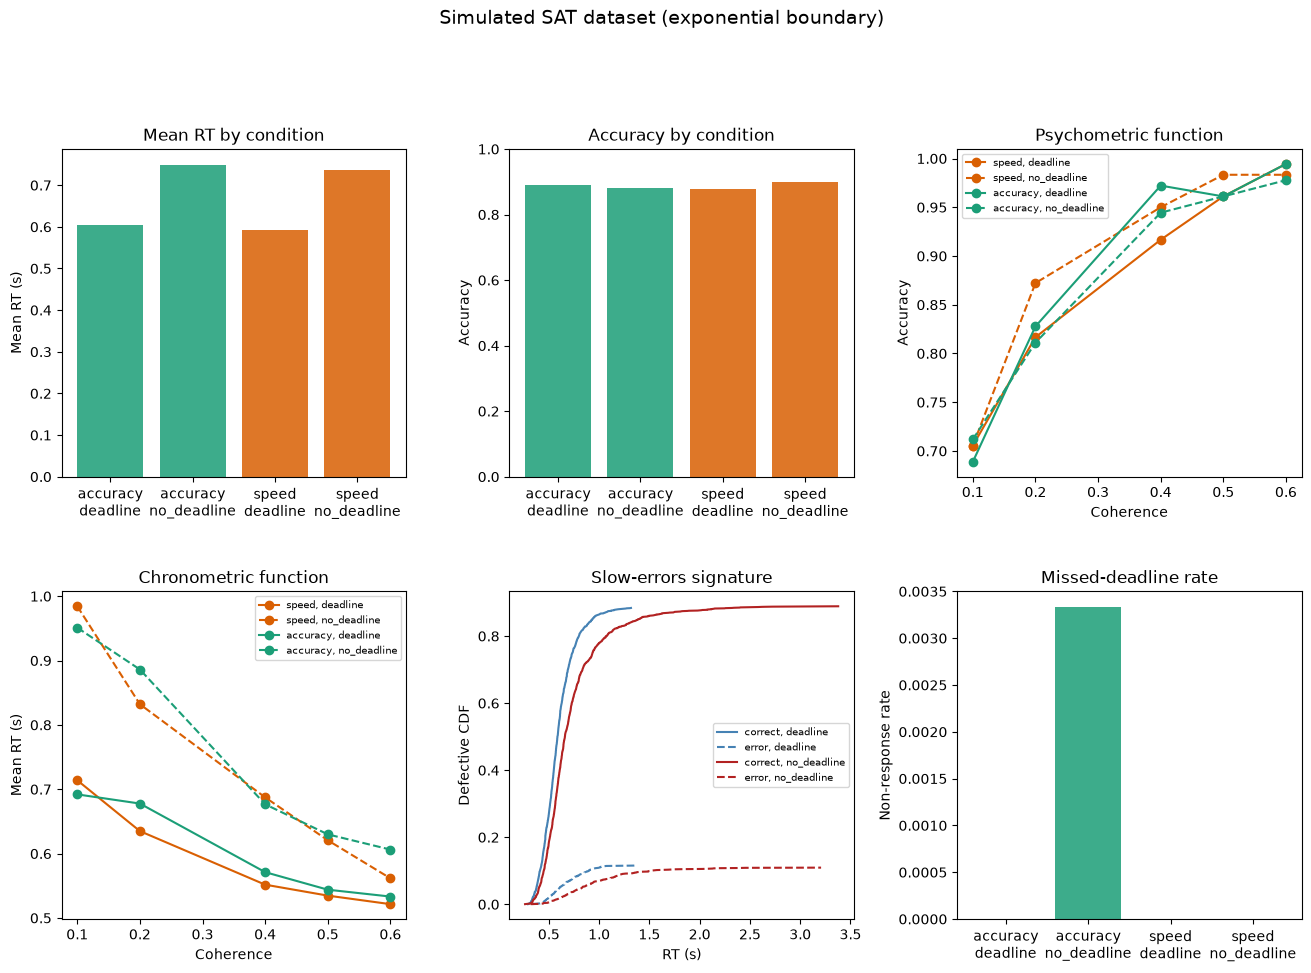

In [201]:
import os
os.makedirs("../data", exist_ok=True)

true_params = []
for model in ["fixed", "linear", "exponential", "sigmoid"]:
    df, params_df = simulate_full_dataset(model=model, n_participants=6, n_trials_per_cell=30, seed=1)
    df.to_csv(f"../data/simulated_data_{model}.csv", index=False)
    params_df["model"] = model
    true_params.append(params_df)

    if model == "exponential":
        plot_insight_summary(df, title=f"Simulated SAT dataset ({model} boundary)")

true_params_df = pd.concat(true_params, ignore_index=True)
true_params_df.to_csv("../data/true_params.csv", index=False)


In [202]:
simulator = bf.make_simulator([prior, likelihood])

sim_draws = simulator.sample(50)

In [203]:
par_keys = [
    "a_base",
    "v_scale",
    "t0",
    "sv",
]
par_names = [r"$a_\text{base}$", r"$v_\text{scale}$", r"$t_0$", r"$sv$"]

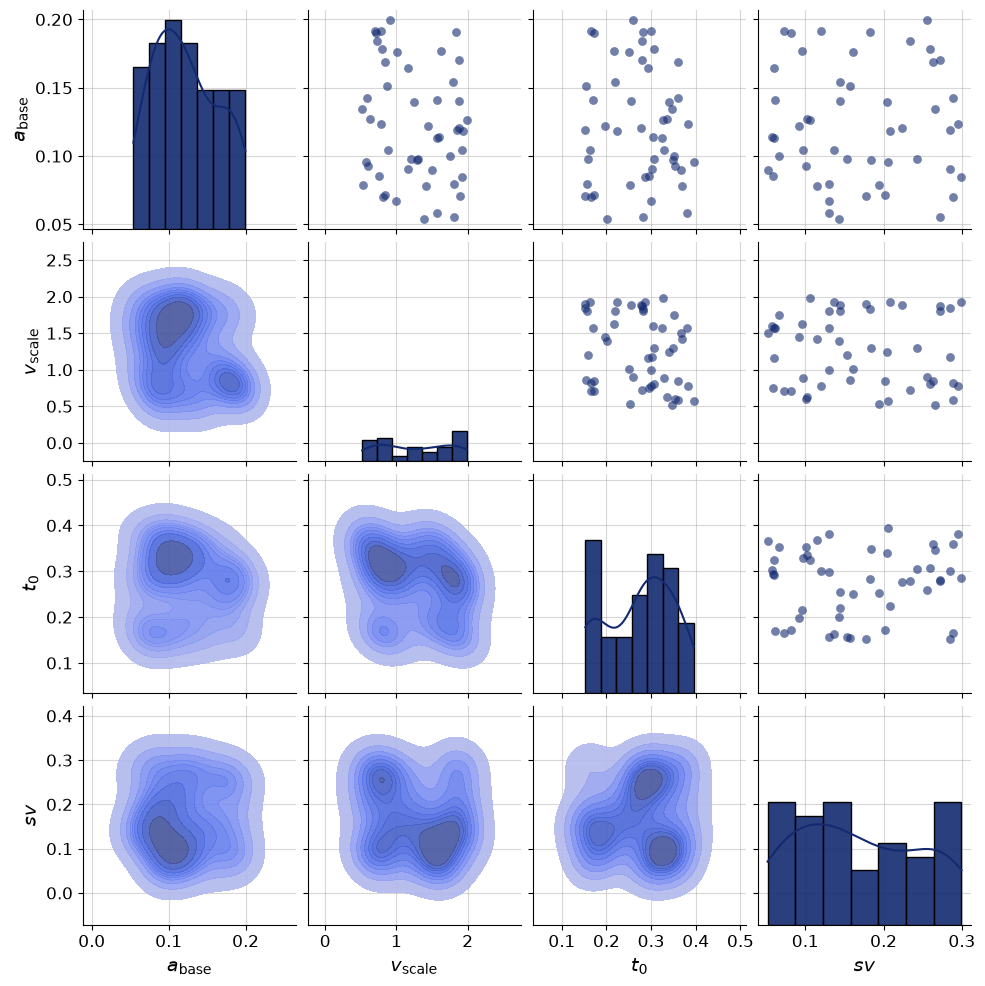

In [204]:
f = bf.diagnostics.plots.pairs_samples(
    samples=sim_draws,
    variable_keys=par_keys,
    variable_names=par_names
)

In [205]:
# 4 Parameter: v_scale, t0, a, lam
num_params = 4

inference_network = bf.networks.CouplingFlow(
    num_params=num_params,
    num_coupling_layers=4,
    coupling_design="interleaved"
)

In [206]:
import tensorflow as tf # Import tensorflow for tf.stack
import keras

@keras.saving.register_keras_serializable()
def stack_trials_for_deepset(data, **kwargs):
    # If the required keys are not present, return data as is.
    # This handles cases where data is already processed or in inverse mode.
    if 'rt' not in data or 'choice' not in data or 'coherence' not in data:
        return data

    # Stack rt, choice, and coherence along a new axis to create a 2D array
    # Each row will be a trial, and columns will be its features (rt, choice, coherence)
    stacked_data = tf.stack([data['rt'], data['choice'], data['coherence']], axis=-1)

    # Create a new dictionary from the input data, keeping all original keys
    # and adding 'summary_variables'. Explicitly remove the original
    # 'rt', 'choice', 'coherence' as they are now combined.
    output_data = {k: v for k, v in data.items() if k not in ['rt', 'choice', 'coherence']}
    output_data['summary_variables'] = stacked_data
    return output_data

adapter = (
    bf.adapters.Adapter()
    .to_array()
    .convert_dtype("float64", "float32")
    # design variables known as conditions (no inference)
    .concatenate(["cue", "has_deadline"], into="inference_conditions")
    # target parameters to be estimated (only the 4 core parameters for inference network)
    .concatenate(["v_scale", "t0", "a_base", "sv"], into="inference_variables")
    # Use add_transform to stack rt, choice, coherence and name the output 'summary_variables'
    .add_transform(stack_trials_for_deepset)
    # Drop 'difficulty' and other parameters not needed for inference/summary networks
    .drop(["difficulty", "model_idx", "k", "lam", "k_sig", "t_mid"])
    .keep(["inference_conditions", "inference_variables", "summary_variables"])
)

In [207]:
import os

CHECKPOINT_DIR = "checkpoints/ddm_sbi_run"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

workflow = bf.BasicWorkflow(
    simulator=simulator,
    adapter=adapter,
    inference_network=inference_network,
    summary_network=bf.networks.SetTransformer(),
    checkpoint_filepath=CHECKPOINT_DIR,
    checkpoint_name="ddm_workflow",
)


Existing checkpoints are not automatically loaded. Upon refitting, the checkpoints will be overwritten.
To load the stored approximator from the checkpoint, use approximator = keras.saving.load_model("checkpoints/ddm_sbi_run/ddm_workflow.keras")


In [208]:
sample = simulator.sample(batch_shape=(8,))

In [209]:
EPOCHS = 1
BATCH_SIZE = 32
history = workflow.fit_online(epochs=EPOCHS, batch_size=BATCH_SIZE, num_batches_per_epoch=20)


history_path = f"bayesflow_history_{int(time.time())}.pkl"
tmp_path = history_path + ".tmp"
with open(tmp_path, "wb") as f:
    pickle.dump(history, f)
os.replace(tmp_path, history_path)

print(f"History saved successfully to {history_path}!")
print(f"Model weights were checkpointed automatically to {CHECKPOINT_DIR}/")


INFO:bayesflow:Fitting on dataset instance of OnlineDataset.
INFO:bayesflow:Building on a test batch.


20/20 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - loss: 5.4627


INFO:bayesflow:Training completed in 43.35 seconds.
INFO:bayesflow:Training is now finished.
You can find the trained approximator at 'checkpoints/ddm_sbi_run/ddm_workflow.keras'.
To load it, use approximator = keras.saving.load_model("checkpoints/ddm_sbi_run/ddm_workflow.keras").


History saved successfully to bayesflow_history_1784416866.pkl!
Model weights were checkpointed automatically to checkpoints/ddm_sbi_run/


In [210]:



if os.path.exists(history_path) and os.path.getsize(history_path) > 0:
    with open(history_path, "rb") as f:
        history = pickle.load(f)
else:
    raise FileNotFoundError(
        f"{history_path} is missing or empty - re-run the training cell above "
        "before continuing."
    )

# If you're continuing in a NEW session (kernel restarted after training),
# reload the actual trained weights here instead of relying on `workflow`,
# which would otherwise be an untrained, freshly-initialized object:
#
# approximator = keras.saving.load_model(os.path.join(CHECKPOINT_DIR, "ddm_workflow.keras"))
#
# and then sample from `approximator` instead of `workflow` below.


/Users/dmahima/Documents/Data Science/sbi/SBI_Project/venv/lib/python3.13/site-packages/bayesflow/diagnostics/plots/loss.py:158: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(train_step_index[0], train_step_index[-1])


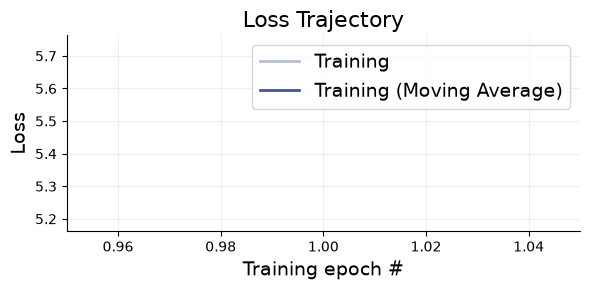

In [211]:
f  = bf.diagnostics.loss(history, figsize=(6,3))

In [212]:
test_data = workflow.simulate(100)

# Pass the RAW simulated data straight to workflow.sample() - it applies the
# adapter internally. Applying `adapter(...)` manually beforehand (as before)
# caused a double-adaptation and the "strict=False before strict=True" error.
samples = workflow.sample(num_samples=1000, conditions=test_data)


Sampling: 100%|██████████| 1/1 [00:01<00:00,  1.34s/batch]
INFO:bayesflow:Sampling completed in 1.75 seconds.


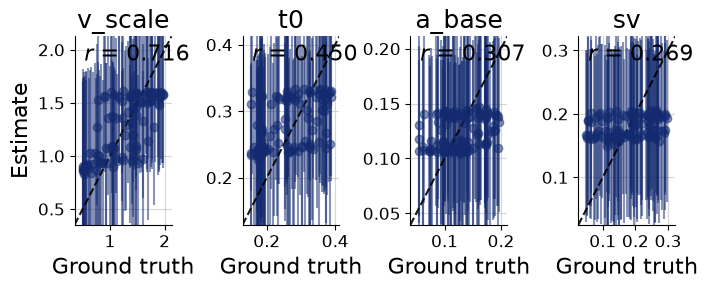

In [213]:
f2 = bf.diagnostics.recovery(samples, test_data, figsize=(7, 3))

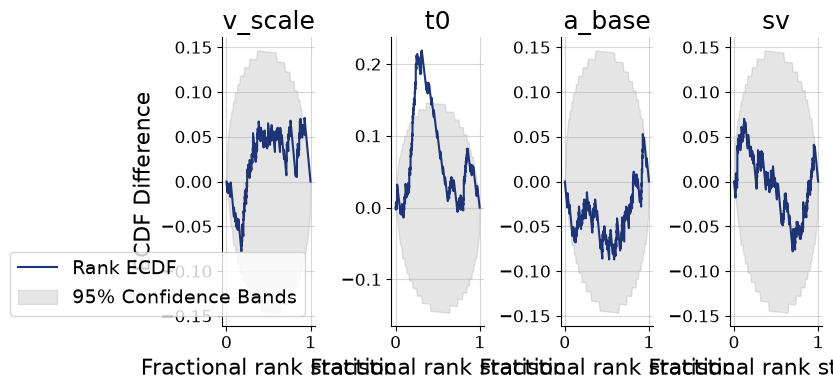

In [214]:
f3 = bf.diagnostics.calibration_ecdf(samples, test_data, figsize=(8, 4))

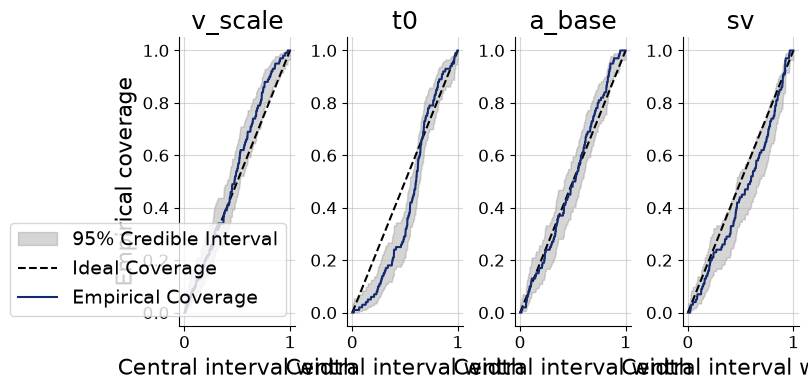

In [215]:
f4 = bf.diagnostics.coverage(samples, test_data, figsize=(8, 4))


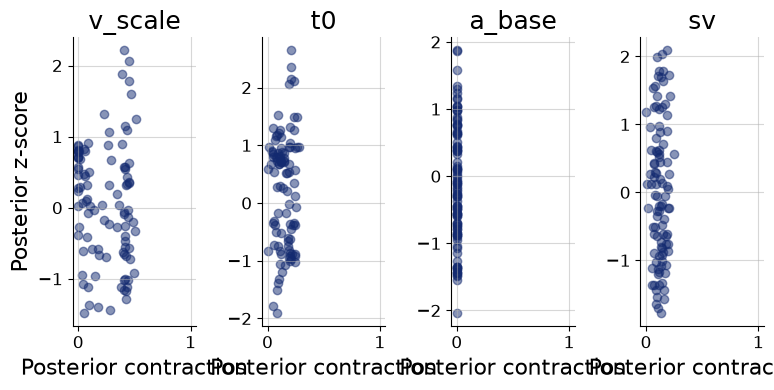

In [216]:
# Posterior contraction
f5 = bf.diagnostics.z_score_contraction(samples, test_data, figsize=(8, 4))
